# Keras Clasificación binaria

# 1.Importación librerías

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 2.Importación fuente de datos

In [2]:
#Lectura datos históricos
df = pd.read_excel('./Heart_diagnosis.xlsx',sheet_name='heart')

# 3.Análisis de Datos (EDA) + Preprocesado

## 3.2 Visualización

### 3.2.1 Plots básicos

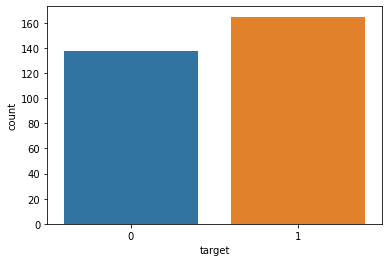

In [10]:
#Verificar si hay una proporción equilibrada entre "0" y "1" para un buen modelado posterior
sns.countplot(x='target',data=df)

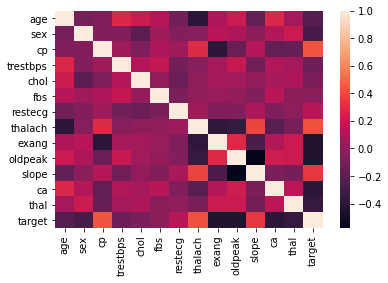

In [11]:
sns.heatmap(df.corr())
#En caso de que haya un error al aplicar el método corr() sobre un dataframe por el hecho de que haya columnas no numéricas (depende de la versión de la librería Pandas), lo más sencillo es aplicar el método con la opción numeric_only=True:
#df.corr(numeric_only = True)

In [12]:
df.corr()['target'].sort_values()
#En caso de que haya un error al aplicar el método corr() sobre un dataframe por el hecho de que haya columnas no numéricas (depende de la versión de la librería Pandas), lo más sencillo es aplicar el método con la opción numeric_only=True:
#df.corr(numeric_only = True)

exang      -0.436757
oldpeak    -0.430696
ca         -0.391724
thal       -0.344029
sex        -0.280937
age        -0.225439
trestbps   -0.144931
chol       -0.085239
fbs        -0.028046
restecg     0.137230
slope       0.345877
thalach     0.421741
cp          0.433798
target      1.000000
Name: target, dtype: float64

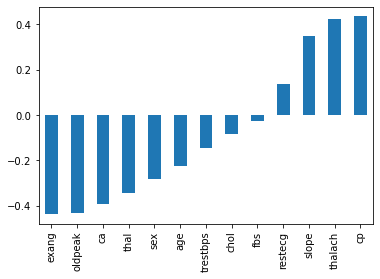

In [13]:
df.corr()['target'][:-1].sort_values().plot(kind='bar') #Quitamos la propia variable objetivo
#En caso de que haya un error al aplicar el método corr() sobre un dataframe por el hecho de que haya columnas no numéricas (depende de la versión de la librería Pandas), lo más sencillo es aplicar el método con la opción numeric_only=True:
#df.corr(numeric_only = True)

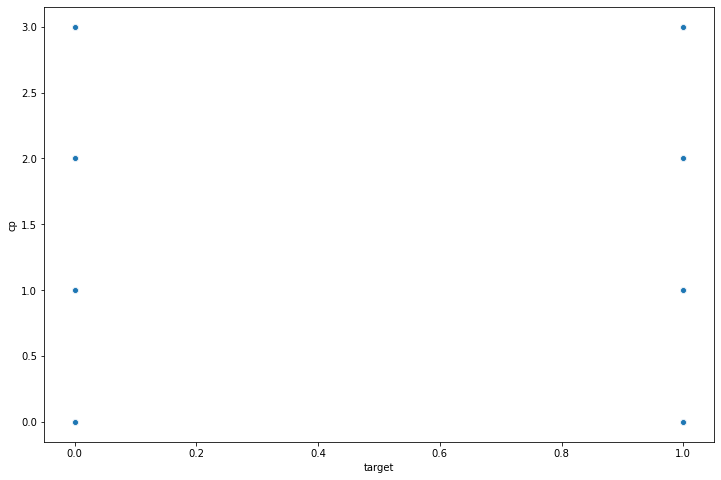

In [14]:
#Visualizar variables altamente correladas con la salida
plt.figure(figsize=(12,8))
sns.scatterplot(x='target',y='cp',data=df)

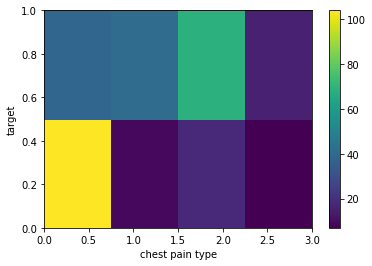

In [15]:
#Si los valores están normalizados, lo mejor es visualizar un histograma 2D
plt.hist2d(df["cp"],df["target"],bins=(4,2),cmap=plt.cm.viridis)
plt.xlabel('chest pain type')
plt.ylabel('target')
plt.colorbar()

### 3.2.2 Plot geográficos

In [16]:
# Visualizar la información geográfica si estuviera completa, el ejemplo que hay a continuación proviende de una 
# fuente de datos alternativa: https://www.kaggle.com/harlfoxem/housesalesprediction
#plt.figure(figsize=(12,8))
#sns.scatterplot(x='price',y='long',data=df)
#plt.figure(figsize=(12,8))
#sns.scatterplot(x='price',y='lat',data=df)
#plt.figure(figsize=(12,8))
#sns.scatterplot(x='long',y='lat',data=df,hue='price') #Representación con poco rango dinámico de colores debido a los outliers
#len(df)*(0.01) #número de muestras que sería el 1% de nuestros datos
#non_top_1_perc = df.sort_values('price',ascending=False).iloc[216:] #estaríamos quitando el 1% de valores outliers
#plt.figure(figsize=(12,8))
#sns.scatterplot(x='long',y='lat',
#                data=non_top_1_perc,hue='price',
#                palette='RdYlGn',edgecolor=None,alpha=0.2) 

### 3.2.3 Otras variables

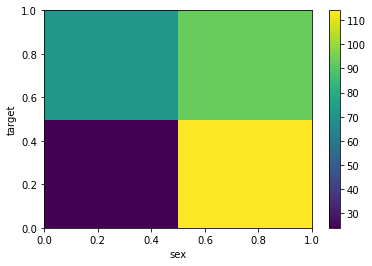

In [17]:
plt.hist2d(df["sex"],df["target"],bins=(2,2),cmap=plt.cm.viridis)
plt.xlabel('sex')
plt.ylabel('target')
plt.colorbar()

## 3.3 Limpieza final (poner atención a ciertos elementos)

In [18]:
# Objetivo: Eliminar variables que no tienen ninguna relación con la variable objetivo (precio) 
# o bien su información ya está incluida en otras variables - Aprovechar conocimiento del campo que estamos tratando

In [19]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        303 non-null    int64  
 12  thal      303 non-null    int64  
 13  target    303 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 45.5 KB


In [20]:
df.corr()['target'].sort_values() #Podríamos eliminar "fbs" = "fasting blood sugar > 120 mg/dl", correlación muy baja
#En caso de que haya un error al aplicar el método corr() sobre un dataframe por el hecho de que haya columnas no numéricas (depende de la versión de la librería Pandas), lo más sencillo es aplicar el método con la opción numeric_only=True:
#df.corr(numeric_only = True)

exang      -0.436757
oldpeak    -0.430696
ca         -0.391724
thal       -0.344029
sex        -0.280937
age        -0.225439
trestbps   -0.144931
chol       -0.085239
fbs        -0.028046
restecg     0.137230
slope       0.345877
thalach     0.421741
cp          0.433798
target      1.000000
Name: target, dtype: float64

### 3.3.2 Limpieza temporal

In [21]:
#Importante visualizar la evolución temporal (si ha habido un importante cambio, quedarse con 
#la porción de datos que corresponde a la situación actual para mejorar la futura predicción)
#El ejemplo que hay a continuación proviende de una fuente de datos alternativa: https://www.kaggle.com/harlfoxem/housesalesprediction

#df['date'] = pd.to_datetime(df['date'])

#df['month'] = df['date'].apply(lambda date:date.month)

#df['year'] = df['date'].apply(lambda date:date.year)

#sns.boxplot(x='year',y='price',data=df)

#sns.boxplot(x='month',y='price',data=df)

#df.groupby('month').mean()['price'].plot()

#df.groupby('year').mean()['price'].plot()

#df = df.drop('date',axis=1) #La fecha no será una variable útil para el modelo

#df['sqft_basement'].value_counts()

### 3.3.3 Transformación variables categóricas

In [22]:
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [23]:
#Utilizar OneHotEncoder si variables categóricas (se obtiene una columna por cada categoría asignando 0 o 1) / Las variables booleanas no es necesario convertirlas True = 1 / False = 0
#from sklearn.preprocessing import OneHotEncoder
#oe_style = OneHotEncoder()
#oe_results = oe_style.fit_transform(df[["body_style"]]) #body_style sería la variable categórica
#pd.DataFrame(oe_results.toarray(), columns=oe_style.categories_).head()
#df = df.join(pd.DataFrame(oe_results.toarray(), columns=oe_style.categories_))

# 4.Train Test Split (no volver a aplicar)

In [24]:
X = df.drop('target',axis=1).values
y = df['target'].values

In [25]:
X.shape

(303, 13)

In [26]:
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [27]:
from sklearn.model_selection import train_test_split

In [28]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.25,random_state=101)

In [29]:
X_train.shape

(227, 13)

In [30]:
X_test.shape

(76, 13)

# 5.Escalado (no volver a aplicar)

In [31]:
from sklearn.preprocessing import MinMaxScaler

In [32]:
scaler = MinMaxScaler()

In [33]:
scaler.fit(X_train)

MinMaxScaler()

In [34]:
X_train = scaler.transform(X_train)
X_test = scaler.transform(X_test)

In [35]:
X_train.shape

(227, 13)

In [36]:
X_test.shape

(76, 13)

In [37]:
X_train

array([[0.79166667, 1.        , 0.        , ..., 0.5       , 0.        ,
        0.66666667],
       [0.70833333, 1.        , 0.        , ..., 1.        , 0.75      ,
        1.        ],
       [0.29166667, 1.        , 0.        , ..., 1.        , 0.        ,
        0.66666667],
       ...,
       [0.35416667, 1.        , 0.33333333, ..., 1.        , 0.        ,
        1.        ],
       [0.25      , 1.        , 0.33333333, ..., 0.5       , 0.        ,
        0.33333333],
       [0.39583333, 0.        , 0.66666667, ..., 1.        , 0.        ,
        0.66666667]])

In [38]:
X_train.max()

1.0

# 6.Creación del modelo

    # Para un problema de clasificación binario
    model.compile(optimizer='rmsprop', # o "adam"
                  loss='binary_crossentropy',
                  metrics=['accuracy'])
                  
    

In [7]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Activation,Dropout

import pandas as pd
import numpy as np

In [8]:
X_train = pd.read_csv('../data/processed/X_test_binario.csv')
y_train = pd.read_csv('../data/processed/Y_test_binario.csv')
X_test = pd.read_csv('../data/processed/X_test_binario.csv')
y_test = pd.read_csv('../data/processed/Y_test_binario.csv')

X_train.shape

(200, 61)

In [11]:
model = Sequential()
# Elegir número de capas (layers)
# https://stats.stackexchange.com/questions/181/how-to-choose-the-number-of-hidden-layers-and-nodes-in-a-feedforward-neural-netw
num_neuronas = X_train.shape[1]
model.add(Dense(units=num_neuronas,activation='relu'))

#model.add(Dense(units=np.round(num_neuronas/2),activation='relu')) SENTENCIA ORIGINAL
model.add(Dense(units=int(np.round(num_neuronas / 2)), activation='relu'))

model.add(Dense(units=1,activation='sigmoid')) # Indicar tantas neuronas de salida como variables a predecir, en este caso solo 1 variable "target"

# Para clasificación binaria "binary_crossentropy"
model.compile(loss='binary_crossentropy', optimizer='adam')

# 7. Entrenamiento del modelo

### Ejemplo 1: Valor alto de epochs y overfitting

In [12]:
# https://stats.stackexchange.com/questions/164876/tradeoff-batch-size-vs-number-of-iterations-to-train-a-neural-network
# https://datascience.stackexchange.com/questions/18414/are-there-any-rules-for-choosing-the-size-of-a-mini-batch

model.fit(x=X_train, 
          y=y_train, 
          epochs=600,
          validation_data=(X_test, y_test), verbose=1
          )

Epoch 1/600
7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 104ms/step - loss: 0.6889 - val_loss: 0.6306
Epoch 2/600
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.6120 - val_loss: 0.5932
Epoch 3/600
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.5871 - val_loss: 0.5784
Epoch 4/600
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.5734 - val_loss: 0.5606
Epoch 5/600
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.5537 - val_loss: 0.5371
Epoch 6/600
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.5299 - val_loss: 0.5130
Epoch 7/600
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.5056 - val_loss: 0.4891
Epoch 8/600
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.4809 - val_loss: 0.4649
Epoch 9/600
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.4565 - val_loss: 0.4417
Epoch 10/600
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.4345 - val_loss: 0.4202
Epoch 11/600
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.4138 - val_loss: 0.4000
Epoch 12/600
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.3943 - val_l

In [13]:
model_loss = pd.DataFrame(model.history.history)

<Axes: >

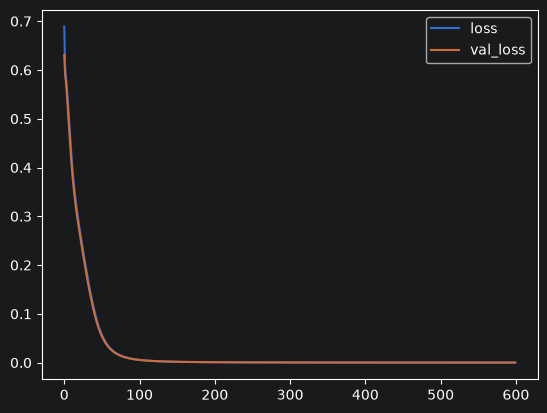

In [14]:
model_loss.plot()

### Ejemplo 2: Early Stopping

Aplicar early stopping para seguir a val_loss y parar en base a la condición indicada

In [16]:
model = Sequential()
model.add(Dense(units=num_neuronas,activation='relu'))
model.add(Dense(units=int(np.round(num_neuronas / 2)), activation='relu'))
#model.add(Dense(units=np.round(num_neuronas/2),activation='relu')) SENTENCIA ORIGINAL
model.add(Dense(units=1,activation='sigmoid')) 
model.compile(loss='binary_crossentropy', optimizer='adam')

In [17]:
from tensorflow.keras.callbacks import EarlyStopping

In [18]:
early_stop = EarlyStopping(monitor='val_loss', mode='min', verbose=1, patience=25)

In [19]:
model.fit(x=X_train, 
          y=y_train, 
          epochs=600,
          validation_data=(X_test, y_test), verbose=1,
          callbacks=[early_stop]
          )

Epoch 1/600
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 96ms/step - loss: 0.7272 - val_loss: 0.6683
Epoch 2/600
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.6436 - val_loss: 0.6171
Epoch 3/600
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.6060 - val_loss: 0.5937
Epoch 4/600
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.5872 - val_loss: 0.5779
Epoch 5/600
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.5721 - val_loss: 0.5614
Epoch 6/600
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.5554 - val_loss: 0.5422
Epoch 7/600
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.5361 - val_loss: 0.5206
Epoch 8/600
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.5144 - val_loss: 0.4995
Epoch 9/600
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.4928 - val_loss: 0.4794
Epoch 10/600
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.4728 - val_loss: 0.4606
Epoch 11/600
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.4549 - val_loss: 0.4425
Epoch 12/600
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.4373 - val_lo

<Axes: >

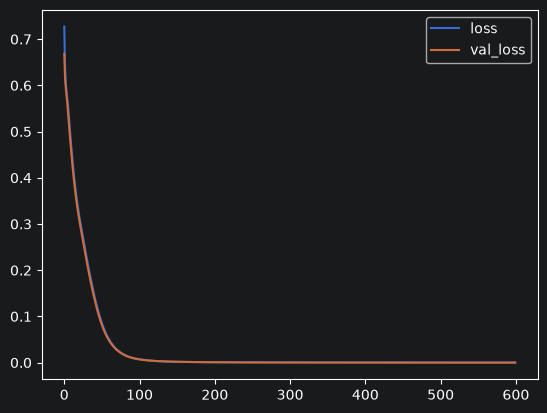

In [20]:
model_loss = pd.DataFrame(model.history.history)
model_loss.plot()

### Ejemplo 3: Añadir DropOut Layers
    #Solo algunas neuronas se actualizarán en cada epoch, permitiendo que solo se ajusten algunos pesos (w) y bias (b) en cada iteración de manera independiente (reduce overfitting)

In [21]:
from tensorflow.keras.layers import Dropout

In [23]:
model = Sequential()

model.add(Dense(units=num_neuronas,activation='relu'))
model.add(Dropout(0.5)) #la mitad de las neuronas en cada epoch para esta capa

# model.add(Dense(units=np.round(num_neuronas/2),activation='relu')) SENTENCIA ORIGINAL
model.add(Dense(units=int(np.round(num_neuronas / 2)), activation='relu'))
model.add(Dropout(0.5)) #la mitad de las neuronas en cada epoch para esta capa

model.add(Dense(units=1,activation='sigmoid'))
model.compile(loss='binary_crossentropy', optimizer='adam')

In [24]:
model.fit(x=X_train, 
          y=y_train, 
          epochs=600,
          validation_data=(X_test, y_test), verbose=1,
          callbacks=[early_stop]
          )

Epoch 1/600
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 105ms/step - loss: 0.9182 - val_loss: 0.7101
Epoch 2/600
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.7966 - val_loss: 0.6464
Epoch 3/600
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.7138 - val_loss: 0.6200
Epoch 4/600
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.6427 - val_loss: 0.6071
Epoch 5/600
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.6570 - val_loss: 0.5987
Epoch 6/600
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.6065 - val_loss: 0.5923
Epoch 7/600
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.6023 - val_loss: 0.5868
Epoch 8/600
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.6334 - val_loss: 0.5816
Epoch 9/600
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.6299 - val_loss: 0.5749
Epoch 10/600
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.6254 - val_loss: 0.5679
Epoch 11/600
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.5918 - val_loss: 0.5620
Epoch 12/600
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.5755 - val_l

<Axes: >

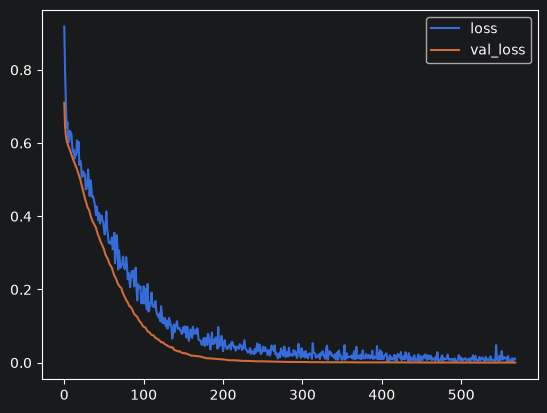

In [25]:
model_loss = pd.DataFrame(model.history.history)
model_loss.plot()

# 8. Evaluación del modelo

In [26]:
from sklearn.metrics import classification_report,confusion_matrix

## 8.1 Predicción sobre el conjunto de Test

In [28]:
#predictions = model.predict_classes(X_test)
#predictions = (model.predict(X_test) > 0.5).astype("int32") #Si nueva versión de scikit-learn

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step


In [29]:
# https://en.wikipedia.org/wiki/Precision_and_recall
print(classification_report(y_test,predictions))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00       140
           1       1.00      1.00      1.00        60

    accuracy                           1.00       200
   macro avg       1.00      1.00      1.00       200
weighted avg       1.00      1.00      1.00       200



In [30]:
print(confusion_matrix(y_test,predictions))

[[140   0]
 [  0  60]]


## 8.2 Predicción sobre nuevos datos

In [61]:
#Lectura datos a predecir
df_pred = pd.read_excel('./Heart_diagnosis.xlsx',sheet_name='Datos_Predecir')
df_pred = df_pred[df.columns] #Filtramos el dataframe predicción para quedarnos con las mismas columnas de interés que el df histórico
X_pred = df_pred.drop('target',axis=1) #Eliminamos la columna objetivo (vacía) si la hubiera en nuestro df con los datos a predecir
X_pred = scaler.transform(X_pred)
#Realizamos predicción
resultado = model.predict_classes(X_pred)
#Unimos en un dataframe los datos a predecir con su predicción
df_pred['PREDICCIÓN']=pd.DataFrame(resultado)
df_pred

C:\Users\ivan_pinar\Anaconda3\lib\site-packages\tensorflow\python\keras\engine\sequential.py:450: UserWarning: `model.predict_classes()` is deprecated and will be removed after 2021-01-01. Please use instead:* `np.argmax(model.predict(x), axis=-1)`,   if your model does multi-class classification   (e.g. if it uses a `softmax` last-layer activation).* `(model.predict(x) > 0.5).astype("int32")`,   if your model does binary classification   (e.g. if it uses a `sigmoid` last-layer activation).
  warnings.warn('`model.predict_classes()` is deprecated and '


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target,PREDICCIÓN
0,60,1,3,145,233,1,0,150,0,2.3,0,0,1,NaN,1
1,42,1,2,130,250,0,1,187,0,3.5,0,0,2,NaN,1
2,40,0,1,130,204,0,0,172,0,1.4,2,0,2,NaN,1
3,55,1,1,120,236,0,1,178,0,0.8,2,0,2,NaN,1
4,62,0,0,120,354,0,1,163,1,0.6,2,0,2,NaN,1
5,58,1,0,140,192,0,1,148,0,0.4,1,0,1,NaN,1
6,55,0,1,140,294,0,0,153,0,1.3,1,0,2,NaN,1
7,34,1,1,120,263,0,1,173,0,0.0,2,0,3,NaN,1
8,50,1,2,172,199,1,1,162,0,0.5,2,0,3,NaN,1
9,59,1,2,150,168,0,1,174,0,1.6,2,0,2,NaN,1


In [78]:
#Guardar y cargar el modelo para posterior uso
from tensorflow.keras.models import load_model
model.save('modelo_pred_heart.h5')